# Loan Delinquency Prediction — Data Scientist I Case Study
**Author:** Priyanshu

This notebook contains the complete workflow. This first part covers **Section 3.1: Data Exploration and Quality Assessment**:

1. Setup and data loading
2. Variable definitions and business context (feature dictionary)
3. Target variable: definition, format, class distribution
4. Data types and the "true" schema
5. Missing values (explicit, hidden, sentinel)
6. Duplicate records and redundant columns
7. Constant / near-constant columns
8. Outliers and implausible values
9. Logical consistency and text-field quality
10. Train vs test distribution shift
11. First look at predictive signal (bad rates, Information Value)
12. Summary of data-quality findings and implications for modelling

Conventions: **Target = 1** means delinquent ("bad"), **0** means non-delinquent ("good"). "Bad rate" means the share of Target = 1.

## 1. Setup and data loading

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = "."
TRAIN_PATH = f"{DATA_DIR}/Assignment_Train.xlsx"
TEST_PATH = f"{DATA_DIR}/Assignment_Test.xlsx"
DICT_PATH = f"{DATA_DIR}/Assignment_FeatureDictionary.xlsx"

ID_COL, TARGET = "UID", "Target"
MISSING_TOKEN = "NaT"   # how the source files encode missing values (see Section 5)
SENTINEL = -1           # "not found in Bureau network" code used by several numeric fields
RANDOM_STATE = 42

# Plot styling: one consistent, colour-blind-safe pair (blue = class 0 / train, orange = class 1 / test)
BLUE, ORANGE, MUTED, GRID, INK = "#2a78d6", "#eb6834", "#898781", "#e1e0d9", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "font.size": 9,
})

In [2]:
train_raw = pd.read_excel(TRAIN_PATH)
test_raw = pd.read_excel(TEST_PATH)
fdict = pd.read_excel(DICT_PATH)

print(f"Train: {train_raw.shape}   Test: {test_raw.shape}   Dictionary: {fdict.shape}")
print("Columns only in train:", sorted(set(train_raw) - set(test_raw)))
print("Columns only in test :", sorted(set(test_raw) - set(train_raw)))
print("Same column order (train without Target vs test):",
      list(train_raw.drop(columns=TARGET).columns) == list(test_raw.columns))

FEATURES = [c for c in train_raw.columns if c not in (ID_COL, TARGET)]
print(f"Candidate input columns: {len(FEATURES)}")
train_raw.head(3).T.head(20)

Train: (10000, 94)   Test: (5000, 93)   Dictionary: (115, 8)
Columns only in train: ['Target']
Columns only in test : []
Same column order (train without Target vs test): True
Candidate input columns: 92


,0,1,2
UID,1,2,3
name,nerella abhilash,ravi kumar choudhary,azgher pasha
Email Attributes.digitalAge,181,181,-1
Email Attributes.domainExists,1,1,1
Email Attributes.domainRiskLevel,Moderate,Moderate,Moderate
Email Attributes.domainUpdatedDate,NaT,NaT,NaT
Email Attributes.domaincorporate,No,No,No
Email Attributes.emailExists,1,1,0
Email Attributes.emailFinalRecommendation,Good,Good,Check
Email Attributes.footprint,HIGH,LOW,LOW


## 2. Variable definitions and business context

The feature dictionary describes each variable with a `category` (data source / Bureau API), a `feature_group`, the expected `impact_direction` and "good"/"bad" ranges.
Names in the dictionary do not match the data columns exactly (e.g. `Email Name Attribute` vs `Email Name Attributes`, `Phone Name` vs `Phone to Name`, the typo `Emial GIN`, and different capitalisation), so I map them with a normalised key.

In [3]:
print("Dictionary columns:", fdict.columns.tolist())

def norm_name(name: str) -> str:
    """Normalise a column name so dictionary entries and data columns can be matched."""
    n = name.lower().replace("emial", "email").replace("phone to name", "phone name").replace("attributes", "attribute")
    return re.sub(r"[^a-z0-9]", "", n)

fdict["key"] = fdict["feature_name"].map(norm_name)
dict_cols = ["feature_name", "category", "feature_group", "impact_direction", "good_range", "bad_range", "description"]

doc = pd.DataFrame({"column": FEATURES})
doc["key"] = doc["column"].map(norm_name)
doc = doc.merge(fdict.drop_duplicates("key").set_index("key")[dict_cols], left_on="key", right_index=True, how="left")

print(f"\n{doc['feature_name'].notna().sum()} of {len(FEATURES)} data columns are documented in the dictionary.")
print("\nData columns with NO dictionary entry:")
print(doc.loc[doc["feature_name"].isna(), "column"].tolist())
print(f"\nDictionary entries not present in the data ({(~fdict['key'].isin(doc['key'])).sum()}):")
print(fdict.loc[~fdict["key"].isin(doc["key"]), "feature_name"].tolist())
print("\nDuplicated dictionary entries:", fdict.loc[fdict["key"].duplicated(keep=False), "feature_name"].tolist())

Dictionary columns: ['feature_name', 'description', 'business_meaning', 'category', 'feature_group', 'impact_direction', 'good_range', 'bad_range']

85 of 92 data columns are documented in the dictionary.

Data columns with NO dictionary entry:
['name', 'Email Attributes.domainUpdatedDate', 'Email Name Attributes.ndrScore', 'Email Name Attributes.phoneNumber', 'Email Name Attributes.unrScore', 'Email GIN.nameDiversity', 'Mobile GIN.nameDiversity']

Dictionary entries not present in the data (29):
['Email Name Attribute.response', 'Email Name Attribute.ccrp', 'Email Name Attribute.emailDigits', 'Email Name Attribute.emailSpclChars', 'Email Social Advance.booking', 'Email Social Advance.email', 'Email Social Advance.github', 'Email Social Advance.moneycontrol', 'Email Attributes.domainCategory', 'Email Attributes.falseCategory', 'Email Attributes.firstVerificationDate', 'Email Attributes.lastVerificationDate', 'Phone Name.ccrp', 'Phone Network.currentNetworkcountryCodeIso2', 'Phone Netwo

In [4]:
# Data columns grouped by source (prefix before the dot) and by the dictionary's feature group
doc["source"] = doc["column"].str.split(".").str[0]
summary = (doc.assign(feature_group=doc["feature_group"].fillna("(undocumented)"))
              .pivot_table(index="source", columns="feature_group", values="column", aggfunc="count", fill_value=0))
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

feature_group,(undocumented),Digital Footprint,Fraud,Identity,Social,Telecom,total
source,,,,,,,
Email Social Advance,0,0,0,0,19,0,19
Phone Social Advance,0,0,0,0,15,0,15
Email Name Attributes,3,0,0,9,0,0,12
Phone Network,0,0,0,2,0,8,10
Email GIN,1,0,7,1,0,0,9
Email Attributes,1,7,1,0,0,0,9
Mobile GIN,1,0,7,1,0,0,9
Phone Name Attributes,0,0,0,7,0,0,7
Phone to Name,0,0,0,1,0,0,1


In [5]:
# Documented expectations: how the business expects each variable to relate to risk
doc.loc[doc["feature_name"].notna(), ["column", "feature_group", "impact_direction", "good_range", "bad_range"]].reset_index(drop=True)

,column,feature_group,impact_direction,good_range,bad_range
0,Email Attributes.digitalAge,Digital Footprint,Higher is safer,>1000 days,<150 days
1,Email Attributes.domainExists,Digital Footprint,Binary indicator,1,0
2,Email Attributes.domainRiskLevel,Fraud,Higher is riskier,Low (Bottom 30%),High (Top 30%)
3,Email Attributes.domaincorporate,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
4,Email Attributes.emailExists,Digital Footprint,Binary indicator,1,0
5,Email Attributes.emailFinalRecommendation,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
6,Email Attributes.footprint,Digital Footprint,Higher is safer,High (Top 30%),Low (Bottom 30%)
7,Email Attributes.uniqueHits,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
8,Email Name Attributes.businessNameDetected,Identity,Context dependent,Review feature-specific distribution,Review feature-specific distribution
9,Email Name Attributes.digitalage,Identity,Higher is safer,>1000 days,<150 days


**Business context by data source.** Every input is a *third-party digital-identity / fraud signal* from Bureau's network, captured at application time:

| Source (prefix) | What it measures | Why it may relate to delinquency |
|---|---|---|
| `Email Attributes` | Whether the email/domain exists, domain risk, email age in the network ("digitalAge"), footprint, Bureau's email recommendation | Old, well-used emails suggest a stable real identity; new or non-existent emails suggest synthetic / throw-away identities |
| `Email Name Attributes` | How well the applicant's name matches the email and the name seen against that email; age of the email+name link | A weak name–email link can mean a borrowed or fabricated identity |
| `Email Social Advance` / `Phone Social Advance` | 0/1 flags for registration on platforms (Amazon, Flipkart, WhatsApp, Paytm, …) | Proxy for real digital life, contactability and lifestyle stability |
| `Phone to Name` / `Phone Name Attributes` | Name registered on UPI, phone age, phone+name link age, footprint strength, number recycling (revocation) | Long-held, personally-registered numbers indicate stability; recycled or new numbers indicate risk |
| `Phone Network` | Carrier, circle (region), prepaid/postpaid, porting history, reachability | Postpaid usually means stronger KYC; porting/region mismatch can signal instability |
| `Email GIN` / `Mobile GIN` | Bureau's Graph Identity Network: fraud flags, number of linked identities (L1/L2), link confidence, name diversity, identity trust | Many identities sharing one email/phone, or links to fraud rings, are classic risk signals |

**Important gap.** The brief mentions "applicant, loan and repayment attributes", but the data contains **no loan-level or repayment variables** (no amount, tenure, income, bureau score or past DPD). The model can only use identity and digital-footprint signals, so moderate discrimination should be expected.

**Undocumented columns.** I interpret them as follows (assumptions):
* `name`: applicant's name (PII, not a feature in itself).
* `Email Name Attributes.phoneNumber`: phone number linked to the email, masked (last 6 digits zeroed). PII.
* `Email Name Attributes.ndrScore` / `unrScore`: name-match ratios in [0, 1] from the email-name service (exact meaning unknown).
* `Email GIN.nameDiversity` / `Mobile GIN.nameDiversity`: share of distinct names linked to the email/phone in the identity graph (in [0, 1]).
* `Email Attributes.domainUpdatedDate`: domain last-updated date (empty in every row).

## 3. Target variable: definition, format and class distribution

The dictionary has no entry for `Target`. Following the brief, `Target` is the **binary loan-delinquency outcome** (1 = became delinquent, 0 = did not).
The exact delinquency definition (e.g. 30+/60+/90+ days past due, observation window) is **not provided**, so it is treated as an assumption.

In [6]:
print("Python types in Target:")
print(train_raw[TARGET].map(lambda v: type(v).__name__).value_counts().to_string(), "\n")
print("Raw values:")
print(train_raw[TARGET].astype(str).value_counts().to_string())

is_labelled = train_raw[TARGET].astype(str).str.strip() != MISSING_TOKEN
y = train_raw.loc[is_labelled, TARGET].astype(int)

dist = y.value_counts().sort_index().rename_axis("Target").to_frame("count")
dist["share_%"] = (100 * dist["count"] / dist["count"].sum()).round(2)
print(f"\nUnlabelled rows (Target = '{MISSING_TOKEN}'): {(~is_labelled).sum()}  -> excluded from training/validation")
print(f"Labelled rows: {len(y)}   bad rate: {y.mean():.2%}   imbalance (good:bad) = {(y == 0).sum() / (y == 1).sum():.1f} : 1")
dist

Python types in Target:
Target
int    9992
str       8 

Raw values:
Target
0      9114
1       878
NaT       8



Unlabelled rows (Target = 'NaT'): 8  -> excluded from training/validation
Labelled rows: 9992   bad rate: 8.79%   imbalance (good:bad) = 10.4 : 1


,count,share_%
Target,,
0,9114,91.21
1,878,8.79


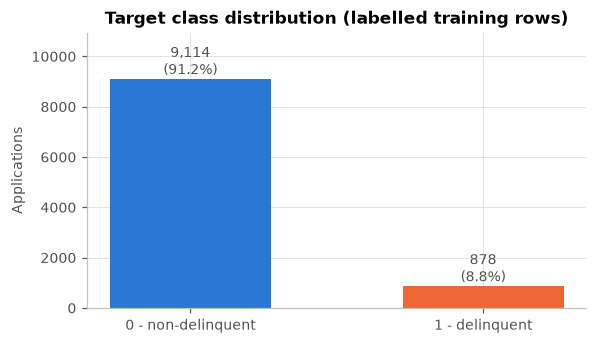

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["0 - non-delinquent", "1 - delinquent"], dist["count"], color=[BLUE, ORANGE], width=0.55)
for b, (n, p) in zip(bars, dist[["count", "share_%"]].values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,.0f}\n({p:.1f}%)", ha="center", va="bottom", color=INK)
ax.set_ylim(0, dist["count"].max() * 1.2)
ax.set_ylabel("Applications")
ax.set_title("Target class distribution (labelled training rows)")
plt.tight_layout(); plt.show()

In [8]:
# The 8 unlabelled rows: do they look otherwise normal?
train_raw.loc[~is_labelled, [ID_COL, "name", "Email Attributes.digitalAge", "Phone Network.currentNetworkName", "Mobile GIN.identityTrust"]]

,UID,name,Email Attributes.digitalAge,Phone Network.currentNetworkName,Mobile GIN.identityTrust
3332,3333,mithun govindaraju raj,0,Airtel,High
3981,3982,umamaheswara reddy patakota,0,Airtel,High
4529,4530,shashikant chandradev kumar,2411,Airtel,Medium
4785,4786,sanket sandeep ambre,2411,Airtel,Medium
6975,6976,jaswant singh kasana,2012,Airtel,Low
7091,7092,kalidass arumugam,407,Airtel,High
8227,8228,mohd shakeel,727,Airtel,Medium
9595,9596,hanumaiah ravikumar,2411,Airtel,Medium


In [9]:
# Is the target related to row order / UID? (would make UID a leaky feature)
uid_trend = (y.groupby(pd.qcut(train_raw.loc[is_labelled, ID_COL], 10, labels=[f"D{i}" for i in range(1, 11)]), observed=True)
               .agg(rows="size", bad_rate="mean"))
uid_trend["bad_rate"] = uid_trend["bad_rate"].round(3)
print("UID ranges: train", train_raw[ID_COL].min(), "-", train_raw[ID_COL].max(),
      "| test", test_raw[ID_COL].min(), "-", test_raw[ID_COL].max())
uid_trend.T

UID ranges: train 1 - 10000 | test 10001 - 15000


UID,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
rows,1000.000,999.00,999.000,999.000,999.000,999.000,999.000,999.000,999.000,1000.00
bad_rate,0.108,0.07,0.106,0.086,0.091,0.086,0.069,0.089,0.093,0.08


**Target, observed:**
* Format: stored as integers 0/1 plus the string `"NaT"` in **8 rows**. Those 8 rows have no label, so they are excluded from model training and validation.
* Class distribution: **9,114 good vs 878 bad (8.79% bad rate)**, an imbalance of about 10 : 1. Accuracy is therefore not a useful metric (predicting "all good" scores 91%). Ranking metrics (ROC-AUC, PR-AUC, KS) and stratified splitting are needed.
* Bad rate by UID decile moves between about 7% and 11% with no monotonic trend. UID is a sequential row ID (train 1–10,000, test 10,001–15,000). It will **not** be used as a feature.

## 4. Data types

The raw dtypes are misleading. Missing values are stored as the literal string `"NaT"`, so many numeric and 0/1 columns load as `object` with a mix of `int`, `float` and `str` values.

In [10]:
def type_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        types = s.map(lambda v: type(v).__name__).value_counts()
        rows.append({
            "column": c,
            "pandas_dtype": str(s.dtype),
            "python_types": ", ".join(f"{t}:{n}" for t, n in types.items()),
            "mixed_types": len(types) > 1,
            "n_unique": s.nunique(),
            "NaT_strings": int((s.astype(str).str.strip() == MISSING_TOKEN).sum()),
            "examples": list(s.dropna().astype(str).unique()[:4]),
        })
    return pd.DataFrame(rows)

tp = type_profile(train_raw)
print("pandas dtypes as loaded:", tp["pandas_dtype"].value_counts().to_dict())
print("Columns with mixed Python types:", tp["mixed_types"].sum())
tp.sort_values(["mixed_types", "NaT_strings"], ascending=False).reset_index(drop=True)

pandas dtypes as loaded: {'object': 50, 'int64': 23, 'str': 16, 'float64': 5}
Columns with mixed Python types: 50


,column,pandas_dtype,python_types,mixed_types,n_unique,NaT_strings,examples
0,Email Social Advance.paytm,object,"str:9978, int:22",True,3,9978,"[NaT, 0, 1]"
1,Phone Social Advance.paytm,object,"str:9974, int:26",True,3,9974,"[NaT, 1, 0]"
2,Email Social Advance.skype,object,"str:9661, int:339",True,3,9661,"[NaT, 0, 1]"
3,Phone Social Advance.skype,object,"str:9587, int:413",True,3,9587,"[NaT, 0, 1]"
4,Phone Network.portedFromNetworkcountryCodeIso2,object,"str:5299, int:4701",True,2,5299,"[91, NaT]"
5,Email Social Advance.pinterest,object,"int:9108, str:892",True,3,892,"[NaT, 0, 1]"
6,Email Social Advance.amazon,object,"int:9182, str:818",True,3,818,"[1, 0, NaT]"
7,Phone Social Advance.amazon,object,"int:9227, str:773",True,3,773,"[1, 0, NaT]"
8,Email Social Advance.zoho,object,"int:9306, str:694",True,3,694,"[0, 1, NaT]"
9,Phone Social Advance.zoho,object,"int:9307, str:693",True,3,693,"[0, NaT, 1]"


To work with the data I define the **semantic schema** explicitly and build a standardisation step:
`"NaT"` becomes a real missing value, numeric/flag columns are cast to numbers, ordinal text levels are kept as ordered labels, and text is trimmed.
`-1` sentinels are **kept as-is** at this stage because they mean "not found in Bureau network", which is information. They are analysed separately below.

In [11]:
PII_COLS = ["name", "Phone to Name.UPIname", "Email Name Attributes.phoneNumber"]
DATE_COLS = ["Email Attributes.domainUpdatedDate", "Phone Name Attributes.revocationMonth"]
ORDINAL_LEVELS = {   # low -> high, per the dictionary's meaning
    "Email Attributes.domainRiskLevel": ["Very Low", "Low", "Moderate", "High", "Very High"],   # "Review" = unrated
    "Email Attributes.emailFinalRecommendation": ["Bad", "Check", "Good"],                      # "No Data" = unrated
    "Email Attributes.footprint": ["NO_RECORDS", "LOW", "MEDIUM", "HIGH"],
    "Email Name Attributes.emailFootprintStrength": ["Very Low", "Low", "Medium", "High", "Very High"],
    "Phone Name Attributes.phoneFootprintStrengthOverall": ["Very Low", "Low", "Medium", "High", "Very High"],
    "Email GIN.identityTrust": ["Low", "Medium", "High"],
    "Mobile GIN.identityTrust": ["Low", "Medium", "High"],
}
NOMINAL_COLS = ["Email Attributes.domaincorporate", "Phone Network.currentNetworkName", "Phone Network.currentNetworkRegion",
                "Phone Network.numberBillingType", "Phone Network.portedFromNetworkName",
                "Phone Network.portedFromNetworkRegion", "Phone Network.portedFromNetworkcountryCodeIso2"]
TEXT_LIKE = PII_COLS[:2] + list(ORDINAL_LEVELS) + NOMINAL_COLS
OTHER_COLS = [c for c in FEATURES if c not in PII_COLS + DATE_COLS + TEXT_LIKE]


def standardise(df: pd.DataFrame) -> pd.DataFrame:
    """Turn the 'NaT' token into NaN and cast every column to its semantic type."""
    out = df.copy()
    for c in out.columns:
        s = out[c].astype(object)
        out[c] = s.mask(s.astype(str).str.strip() == MISSING_TOKEN)
    for c in OTHER_COLS + ["Email Name Attributes.phoneNumber"]:
        # raises if any non-numeric junk remains; float keeps train/test dtypes identical whether or not NaN is present
        out[c] = pd.to_numeric(out[c], errors="raise").astype(float)
    for c in DATE_COLS:
        out[c] = pd.to_datetime(out[c], errors="raise")
    for c in TEXT_LIKE:
        out[c] = out[c].astype("string").str.strip()
    return out


train_all = standardise(train_raw)
train = train_all.loc[is_labelled].copy()
train[TARGET] = y
test = standardise(test_raw)

BINARY_COLS = [c for c in OTHER_COLS if set(train_all[c].dropna().unique()) <= {0, 1}]
NUMERIC_COLS = [c for c in OTHER_COLS if c not in BINARY_COLS]

schema = pd.Series({**{c: "ID" for c in [ID_COL]}, **{c: "PII / free text" for c in PII_COLS},
                    **{c: "date" for c in DATE_COLS}, **{c: "ordinal categorical" for c in ORDINAL_LEVELS},
                    **{c: "nominal categorical" for c in NOMINAL_COLS}, **{c: "binary flag" for c in BINARY_COLS},
                    **{c: "numeric" for c in NUMERIC_COLS}}, name="semantic_type")
print("All non-'NaT' values converted cleanly (no coercion errors).")
print(schema.value_counts().to_string())
print("\nNumeric columns:", NUMERIC_COLS)

All non-'NaT' values converted cleanly (no coercion errors).
semantic_type
binary flag            53
numeric                20
ordinal categorical     7
nominal categorical     7
PII / free text         3
date                    2
ID                      1

Numeric columns: ['Email Attributes.digitalAge', 'Email Attributes.uniqueHits', 'Email Name Attributes.digitalage', 'Email Name Attributes.emailNameDigitalAge', 'Email Name Attributes.nameEmailMatch', 'Email Name Attributes.nameMatchScore', 'Email Name Attributes.ndrScore', 'Email Name Attributes.unrScore', 'Phone Name Attributes.digitalage', 'Phone Name Attributes.phoneNameDigitalAge', 'Email GIN.nameDiversity', 'Email GIN.l1Confidence', 'Email GIN.l1Count', 'Email GIN.l2Count', 'Email GIN.l2Confidence', 'Mobile GIN.nameDiversity', 'Mobile GIN.l1Confidence', 'Mobile GIN.l1Count', 'Mobile GIN.l2Count', 'Mobile GIN.l2Confidence']


In [12]:
# Category levels present in train vs test, for the text columns
pd.DataFrame({c: {"train_levels": sorted(train[c].dropna().unique().tolist()),
                  "test_levels_not_in_train": sorted(set(test[c].dropna()) - set(train[c].dropna()))}
              for c in list(ORDINAL_LEVELS) + NOMINAL_COLS}).T

,train_levels,test_levels_not_in_train
Email Attributes.domainRiskLevel,"[High, Low, Moderate, Review, Very High, Very Low]",[]
Email Attributes.emailFinalRecommendation,"[Bad, Check, Good, No Data]",[]
Email Attributes.footprint,"[HIGH, LOW, MEDIUM, NO_RECORDS]",[]
Email Name Attributes.emailFootprintStrength,"[High, Low, Very High, Very Low]",[]
Phone Name Attributes.phoneFootprintStrengthOverall,"[High, Low, Medium, Very High]",[]
Email GIN.identityTrust,"[High, Low, Medium]",[]
Mobile GIN.identityTrust,"[High, Low, Medium]",[]
Email Attributes.domaincorporate,"[No, Yes]",[]
Phone Network.currentNetworkName,"[Airtel, BSNL, IDEA, MTNL, Reliance Jio, Vodafone]",[]
Phone Network.currentNetworkRegion,"[Andhra Pradesh, Assam, Bihar and Jharkhand, Chennai, Delhi, Gujarat, Haryan...",[]


## 5. Missing values

There are three layers of missingness:
1. **Explicit NaN:** none. `isna()` on the raw files reports 0 everywhere, which is misleading.
2. **Hidden `"NaT"` tokens:** service returned nothing for that field.
3. **`-1` sentinel:** documented for `Email Attributes.digitalAge` ("absence of email in Bureau network") and used the same way in other digital-age / name-match fields.

In [13]:
print("Explicit NaN in raw train:", int(train_raw.isna().sum().sum()), "| raw test:", int(test_raw.isna().sum().sum()))

def missing_profile(df: pd.DataFrame) -> pd.DataFrame:
    nat = df[FEATURES].isna().mean()
    sent = df[FEATURES].apply(lambda s: pd.to_numeric(s, errors="coerce").eq(SENTINEL).mean())
    return pd.DataFrame({"NaT_%": 100 * nat, "minus1_%": 100 * sent, "effective_%": 100 * (nat + sent)})

mp = missing_profile(train).add_prefix("train_").join(missing_profile(test).add_prefix("test_"))
mp = mp[(mp > 0).any(axis=1)].sort_values("train_effective_%", ascending=False).round(2)
print(f"Columns with any NaT or -1: {len(mp)} of {len(FEATURES)}")
mp

Explicit NaN in raw train: 0 | raw test: 0


Columns with any NaT or -1: 63 of 92


,train_NaT_%,train_minus1_%,train_effective_%,test_NaT_%,test_minus1_%,test_effective_%
Email Attributes.domainUpdatedDate,100.00,0.0,100.0,100.00,0.0,100.0
Email Social Advance.paytm,99.78,0.0,99.779824,99.82,0.0,99.82
Phone Social Advance.paytm,99.74,0.0,99.739792,99.84,0.0,99.84
Phone Name Attributes.revocationMonth,98.80,0.0,98.799039,98.46,0.0,98.46
Email Social Advance.skype,96.61,0.0,96.607286,97.24,0.0,97.24
Phone Social Advance.skype,95.88,0.0,95.876701,96.12,0.0,96.12
Email Name Attributes.phoneNumber,0.00,84.207366,84.207366,0.00,88.32,88.32
Email Name Attributes.emailNameDigitalAge,0.02,80.404323,80.424339,0.04,84.96,85.0
Email Name Attributes.nameMatchScore,0.00,74.619696,74.619696,0.00,80.78,80.78
Email Name Attributes.ndrScore,0.00,74.049239,74.049239,0.00,80.26,80.26


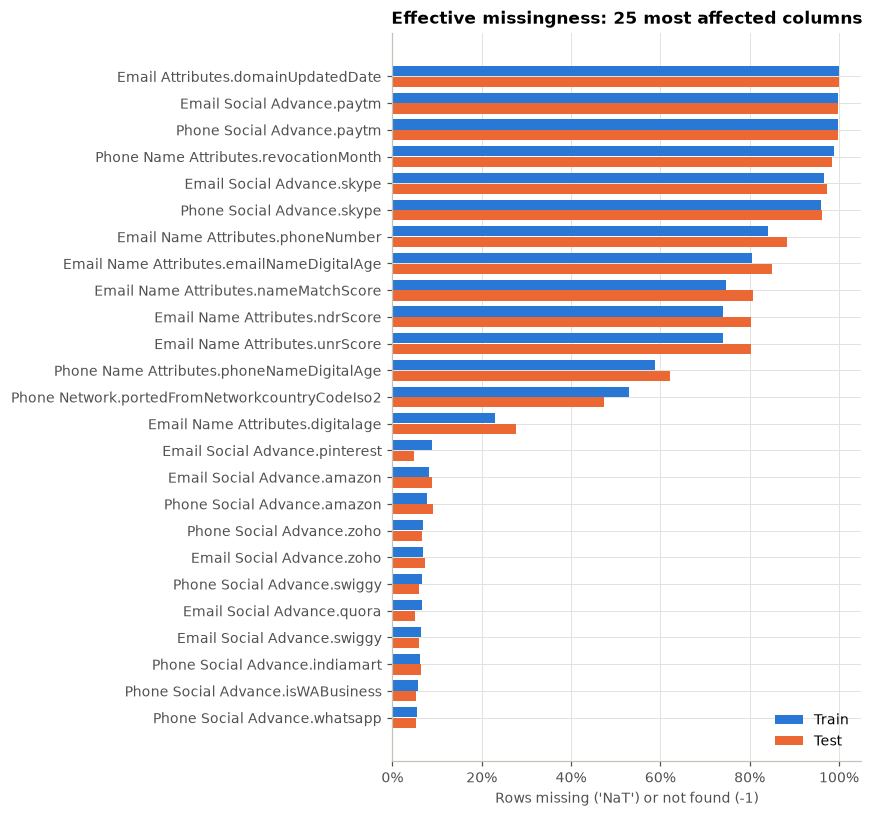

In [14]:
top = mp.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7.5))
pos = np.arange(len(top))
ax.barh(pos + 0.2, top["train_effective_%"], height=0.38, color=BLUE, label="Train")
ax.barh(pos - 0.2, top["test_effective_%"], height=0.38, color=ORANGE, label="Test")
ax.set_yticks(pos, top.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Rows missing ('NaT') or not found (-1)")
ax.set_title("Effective missingness: 25 most affected columns")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Missingness comes in blocks.** Whole services are absent together, so the missing values are *structural*, not random:

In [15]:
eff_missing = lambda df: df[FEATURES].isna() | df[FEATURES].apply(lambda s: pd.to_numeric(s, errors="coerce").eq(SENTINEL))
M = eff_missing(train)

blocks = {
    "Email GIN (9 graph columns)": [c for c in FEATURES if c.startswith("Email GIN.")],
    "Email-name match (nameMatchScore, ndr, unr, phoneNumber)": ["Email Name Attributes.nameMatchScore", "Email Name Attributes.ndrScore",
                                                                  "Email Name Attributes.unrScore", "Email Name Attributes.phoneNumber"],
    "Ported-from details (name, region, country)": ["Phone Network.portedFromNetworkName", "Phone Network.portedFromNetworkRegion",
                                                    "Phone Network.portedFromNetworkcountryCodeIso2"],
    "Email social flags (all 19)": [c for c in FEATURES if c.startswith("Email Social Advance.")],
    "Phone social flags (all 15)": [c for c in FEATURES if c.startswith("Phone Social Advance.")],
}
pd.DataFrame({name: {"rows_any_missing_%": 100 * M[cols].any(axis=1).mean(),
                     "rows_all_missing_%": 100 * M[cols].all(axis=1).mean()} for name, cols in blocks.items()}).T.round(2)

,rows_any_missing_%,rows_all_missing_%
Email GIN (9 graph columns),0.52,0.35
"Email-name match (nameMatchScore, ndr, unr, phoneNumber)",84.21,74.05
"Ported-from details (name, region, country)",58.43,53.01
Email social flags (all 19),99.87,0.00
Phone social flags (all 15),99.97,0.00


In [16]:
# Ported-from fields are *structurally* empty when the number was never ported
port = pd.crosstab(train["Phone Network.numberHasPortingHistory"],
                   train["Phone Network.portedFromNetworkName"].isna().map({True: "portedFrom missing", False: "portedFrom present"}))
port

Phone Network.portedFromNetworkName,portedFrom missing,portedFrom present
Phone Network.numberHasPortingHistory,,
0.0,5297,0
1.0,541,4154


**Is missingness informative?** Compare the bad rate when a field is missing / not found vs present. Fields where the gap is large should get an explicit missing-indicator (or a dedicated bin) instead of plain imputation.

In [17]:
overall_bad = train[TARGET].mean()
rows = []
for c in FEATURES:
    m = M[c]
    if m.sum() >= 30 and (~m).sum() >= 30:
        rows.append({"column": c, "n_missing": int(m.sum()), "bad_rate_missing": train.loc[m, TARGET].mean(),
                     "bad_rate_present": train.loc[~m, TARGET].mean()})
inf = pd.DataFrame(rows)
inf["lift_missing_vs_present"] = inf["bad_rate_missing"] / inf["bad_rate_present"]
inf.sort_values("lift_missing_vs_present", ascending=False).round(3).reset_index(drop=True)

,column,n_missing,bad_rate_missing,bad_rate_present,lift_missing_vs_present
0,Email Social Advance.skype,9653,0.090,0.027,3.391
1,Email Name Attributes.phoneNumber,8414,0.097,0.041,2.346
2,Email Name Attributes.emailNameDigitalAge,8036,0.098,0.045,2.185
3,Phone Social Advance.skype,9580,0.090,0.046,1.944
4,Phone Social Advance.instagram,30,0.167,0.088,1.902
5,Email Name Attributes.nameMatchScore,7456,0.099,0.055,1.808
6,Email Social Advance.jeevansaathi,212,0.156,0.086,1.802
7,Email Social Advance.flickr,51,0.157,0.088,1.792
8,Email Social Advance.toi,91,0.154,0.087,1.763
9,Email Name Attributes.unrScore,7399,0.099,0.056,1.757


## 6. Duplicate records and redundant columns

In [18]:
# NaN -> explicit "missing" label so comparisons treat missing values as equal (pandas 3 keeps NaN under astype(str))
as_text = lambda df: df.astype(object).where(df.notna(), "missing").astype(str)
key = lambda df: as_text(df[FEATURES])
print("Duplicate UIDs   - train:", train_raw[ID_COL].duplicated().sum(), "| test:", test_raw[ID_COL].duplicated().sum(),
      "| UIDs shared by train & test:", len(set(train_raw[ID_COL]) & set(test_raw[ID_COL])))
print("Exact duplicate rows (all features, ignoring UID/Target) - train:", key(train_all).duplicated().sum(),
      "| test:", key(test).duplicated().sum())
print("Exact feature-row matches between train and test:", key(train_all).merge(key(test), how="inner").shape[0])

norm_person = lambda df: df["name"].str.lower().str.split().str.join(" ")
print("\nRows sharing a name with another train row:", norm_person(train_all).duplicated(keep=False).sum())

# Same name AND same email / phone digital ages -> likely the same person applying twice
pkey = ["name", "Email Attributes.digitalAge", "Phone Name Attributes.digitalage", "Phone Network.currentNetworkRegion"]
person = lambda df: as_text(df.assign(name=norm_person(df))[pkey])
near = train_all[person(train_all).duplicated(keep=False)]
print("Likely repeat applicants within train (name + email age + phone age + region):", len(near), "rows")
print("Likely same applicant in both train and test:", person(train_all).merge(person(test).drop_duplicates(), how="inner").shape[0])
print("\nMost repeated names (common names, different people):")
norm_person(train_all).value_counts().head(5)

Duplicate UIDs   - train: 0 | test: 0 | UIDs shared by train & test: 0


Exact duplicate rows (all features, ignoring UID/Target) - train: 0 | test: 0


Exact feature-row matches between train and test: 0

Rows sharing a name with another train row: 1191
Likely repeat applicants within train (name + email age + phone age + region): 0 rows
Likely same applicant in both train and test: 0

Most repeated names (common names, different people):


name
amit kumar        30
rahul kumar       19
sunil kumar       18
sandeep kumar     17
abhishek kumar    15
Name: count, dtype: int64

In [19]:
# Columns that are exact copies of each other (after standardisation)
cols = [c for c in FEATURES if c not in PII_COLS]
fp = as_text(train_all[cols])
seen, dup_pairs = {}, []
for c in cols:
    sig = tuple(fp[c])
    if sig in seen:
        dup_pairs.append((seen[sig], c))
    else:
        seen[sig] = c
pd.DataFrame(dup_pairs, columns=["kept", "identical_copy"])

,kept,identical_copy
0,Email Name Attributes.businessNameDetected,Phone Name Attributes.businessNameDetected
1,Phone Network.isPhoneReachable,Phone Network.isValidPhoneNumber
2,Phone Name Attributes.ccrp,Phone Network.roaming
3,Email GIN.fraudCount,Email GIN.fraud
4,Phone Name Attributes.ccrp,Mobile GIN.fraudCount
5,Phone Name Attributes.ccrp,Mobile GIN.fraud


**Observed:** no duplicate UIDs, no duplicate feature rows and no train–test row overlap. 1,191 train rows share a name with another row, but these are common Indian names. **No pair** also shares the same email age, phone age and region, so there is no evidence of repeat applicants or train–test leakage through duplicates.

Identical columns:
* `Email Name Attributes.businessNameDetected` = `Phone Name Attributes.businessNameDetected` in every row. That is suspicious for two different services and suggests a pipeline/join issue. Keep one.
* `Email GIN.fraud` = `Email GIN.fraudCount`. Both are only ever 0 or missing; **no email in the data is flagged for fraud**.
* The remaining pairs are constant columns (next section).

## 7. Constant and near-constant columns

In [20]:
def dominance(df):
    txt = as_text(df[FEATURES])
    return pd.DataFrame({
        "n_unique_incl_missing": txt.nunique(),
        "top_value": txt.mode().iloc[0],
        "top_share_%": 100 * txt.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    })

dom = dominance(train_all).join(dominance(test)[["top_share_%"]].rename(columns={"top_share_%": "test_top_share_%"}))
dom = dom[dom["top_share_%"] >= 99].sort_values("top_share_%", ascending=False).round(2)
CONSTANT_COLS = dom.index[dom["n_unique_incl_missing"] == 1].tolist()
print("Constant in train (no information):", CONSTANT_COLS)
dom

Constant in train (no information): ['Email Attributes.domainUpdatedDate', 'Phone Network.isValidPhoneNumber', 'Phone Network.isPhoneReachable', 'Phone Name Attributes.ccrp', 'Mobile GIN.fraudCount', 'Mobile GIN.fraud', 'Phone Network.roaming']


,n_unique_incl_missing,top_value,top_share_%,test_top_share_%
Email Attributes.domainUpdatedDate,1,missing,100.00,100.00
Phone Network.isValidPhoneNumber,1,1.0,100.00,100.00
Phone Network.isPhoneReachable,1,1.0,100.00,100.00
Phone Name Attributes.ccrp,1,0.0,100.00,100.00
Mobile GIN.fraudCount,1,0.0,100.00,100.00
Mobile GIN.fraud,1,0.0,100.00,100.00
Phone Network.roaming,1,0.0,100.00,100.00
Mobile GIN.fraudNetwork,2,0.0,99.88,99.90
Email Social Advance.paytm,3,missing,99.78,99.82
Phone Social Advance.paytm,3,missing,99.74,99.84


The 7 constant columns (`Phone Name Attributes.ccrp`, `Phone Network.isPhoneReachable`, `isValidPhoneNumber`, `roaming`, `Mobile GIN.fraud`, `Mobile GIN.fraudCount`, `Email Attributes.domainUpdatedDate`) carry no information and will be dropped.
Several *fraud* flags are almost always 0 (`Email GIN.fraudNetwork` = 1 in only 7 rows, `Mobile GIN.fraudNetwork` in 11, `Email GIN.fraud` never). Bad rates on such tiny groups are unreliable, so these are low-value features unless combined into a broader flag.

## 8. Outliers and implausible values

Statistics below exclude the `-1` sentinel and missing values, so they describe genuine observations only.

In [21]:
def describe_numeric(df):
    rows = []
    for c in NUMERIC_COLS:
        v = df[c][df[c].notna() & df[c].ne(SENTINEL)]
        q1, q3 = v.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows.append({"column": c, "n": len(v), "min": v.min(), "p1": v.quantile(.01), "median": v.median(),
                     "p99": v.quantile(.99), "max": v.max(), "skew": v.skew(),
                     "iqr_outlier_%": 100 * ((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).mean(),
                     "other_negatives": int((df[c] < 0).sum() - df[c].eq(SENTINEL).sum())})
    return pd.DataFrame(rows).set_index("column")

describe_numeric(train).round(2)

,n,min,p1,median,p99,max,skew,iqr_outlier_%,other_negatives
column,,,,,,,,,
Email Attributes.digitalAge,9819,0.00,0.00,407.0,4740.92,7134.0,0.79,0.11,0
Email Attributes.uniqueHits,9992,0.00,0.00,7.0,16.00,26.0,0.28,0.77,0
Email Name Attributes.digitalage,7693,0.00,18.00,1778.0,4616.28,5730.0,0.73,2.57,0
Email Name Attributes.emailNameDigitalAge,1956,21.00,948.55,1790.0,4300.45,5717.0,1.48,7.21,0
Email Name Attributes.nameEmailMatch,9992,0.00,0.00,61.0,96.00,100.0,-0.66,0.00,0
Email Name Attributes.nameMatchScore,2536,6.00,13.00,91.0,100.00,100.0,-1.90,5.17,0
Email Name Attributes.ndrScore,2593,0.00,0.00,1.0,1.00,1.0,-3.77,6.90,0
Email Name Attributes.unrScore,2593,0.00,0.00,0.0,1.00,1.0,1.62,22.29,0
Phone Name Attributes.digitalage,9583,0.00,18.82,1799.0,4940.54,36411.0,3.95,2.48,0


In [22]:
# Domain plausibility rules
DAYS_30Y, DAYS_25Y = 30 * 365, 25 * 365
age_cols = [c for c in NUMERIC_COLS if "igital" in c or "DigitalAge" in c]
rules = {
    "Phone digital age > 30 years (mobile in India since 1995)": lambda d: d["Phone Name Attributes.digitalage"] > DAYS_30Y,
    "Phone+name age > 30 years": lambda d: d["Phone Name Attributes.phoneNameDigitalAge"] > DAYS_30Y,
    "Any email digital age > 25 years": lambda d: (d[[c for c in age_cols if "mail" in c]] > DAYS_25Y).any(axis=1),
    "Email GIN L1 count >= 100 (dictionary: >4 already risky)": lambda d: d["Email GIN.l1Count"] >= 100,
    "Email GIN L2 count >= 100": lambda d: d["Email GIN.l2Count"] >= 100,
    "Mobile GIN L2 count >= 100": lambda d: d["Mobile GIN.l2Count"] >= 100,
}
pd.DataFrame({r: {"train_rows": int(f(train_all).sum()), "test_rows": int(f(test).sum())} for r, f in rules.items()}).T

,train_rows,test_rows
Phone digital age > 30 years (mobile in India since 1995),1,0
Phone+name age > 30 years,0,0
Any email digital age > 25 years,0,0
Email GIN L1 count >= 100 (dictionary: >4 already risky),1,0
Email GIN L2 count >= 100,3,2
Mobile GIN L2 count >= 100,73,43


In [23]:
print("Values of the extreme graph counts (they cluster around ~500, i.e. a cap / placeholder rather than real counts):")
for c in ["Email GIN.l1Count", "Email GIN.l2Count", "Mobile GIN.l2Count"]:
    print(f"  {c:22s}", sorted(pd.concat([train_all[c], test[c]]).loc[lambda s: s >= 100].astype(int).tolist()))
print("Max phone digital age:", train_all["Phone Name Attributes.digitalage"].max(), "days =",
      round(train_all["Phone Name Attributes.digitalage"].max() / 365, 1), "years")

Values of the extreme graph counts (they cluster around ~500, i.e. a cap / placeholder rather than real counts):
  Email GIN.l1Count      [500]
  Email GIN.l2Count      [185, 192, 505, 505, 506]
  Mobile GIN.l2Count     [101, 101, 105, 108, 109, 110, 111, 116, 116, 116, 120, 134, 136, 137, 143, 144, 166, 169, 178, 181, 182, 190, 196, 202, 202, 213, 215, 216, 230, 242, 242, 255, 259, 267, 272, 283, 291, 311, 317, 318, 325, 337, 339, 352, 358, 359, 374, 393, 418, 437, 442, 445, 452, 461, 489, 496, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 506, 506, 506, 506, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 508, 508, 508, 508, 508, 508, 508, 508, 508, 509, 509, 510, 517]
Max phone digital age: 36411.0 days = 99.8 years


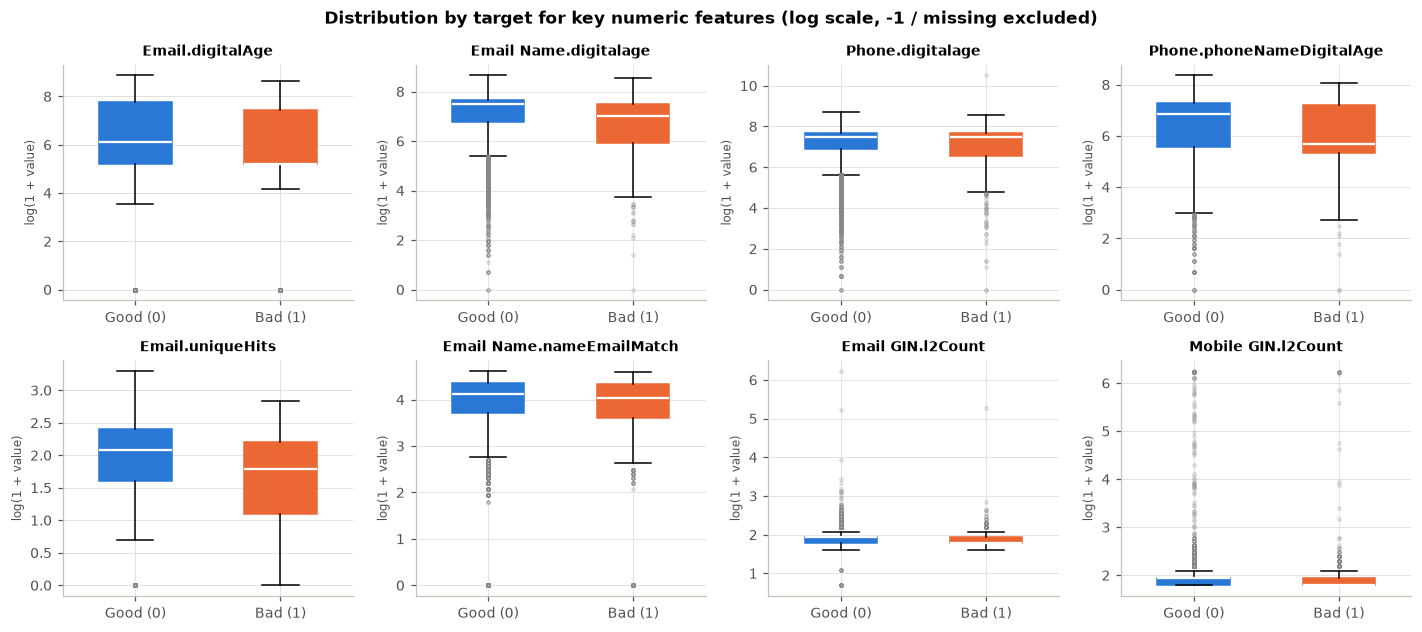

In [24]:
plot_cols = ["Email Attributes.digitalAge", "Email Name Attributes.digitalage", "Phone Name Attributes.digitalage",
             "Phone Name Attributes.phoneNameDigitalAge", "Email Attributes.uniqueHits", "Email Name Attributes.nameEmailMatch",
             "Email GIN.l2Count", "Mobile GIN.l2Count"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8))
for ax, c in zip(axes.ravel(), plot_cols):
    data = [np.log1p(train.loc[(train[TARGET] == k) & train[c].ge(0), c]) for k in (0, 1)]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=2, alpha=0.3, markeredgecolor=MUTED),
                    medianprops=dict(color="white", linewidth=1.5))
    for patch, col in zip(bp["boxes"], (BLUE, ORANGE)):
        patch.set_facecolor(col); patch.set_edgecolor(col)
    ax.set_xticks([1, 2], ["Good (0)", "Bad (1)"])
    ax.set_title(c.replace(" Attributes", "").replace("Phone Name", "Phone"), fontsize=9)
    ax.set_ylabel("log(1 + value)", fontsize=8)
fig.suptitle("Distribution by target for key numeric features (log scale, -1 / missing excluded)", fontweight="bold")
plt.tight_layout(); plt.show()

**Outlier observations:**
* Digital ages are strongly right-skewed (from 0 days to about 13–20 years) but mostly plausible. One phone digital age of **36,411 days (about 100 years)** is impossible and should be treated as an error (cap or set to missing).
* Graph link counts (`l1Count`, `l2Count`) have a small cluster of values around **500**. This looks like a system cap/placeholder rather than a real count. These are also the extreme "fraud-ring" profiles, so they should be **capped and flagged**, not deleted.
* IQR "outliers" in confidence/diversity scores are not errors. Those variables are bunched at 1.0, so any value below 1 is flagged by the IQR rule.
* Rows are **not dropped** for outliers. The plan is to winsorise / cap (or rely on tree-based models, which are insensitive to monotone scaling).

## 9. Logical consistency and text-field quality

In [25]:
email_age_gap = lambda d: (d["Email Attributes.digitalAge"] - d["Email Name Attributes.digitalage"]).abs()
checks = {
    "email+name link older than the email itself": lambda d: (d["Email Name Attributes.emailNameDigitalAge"] > d["Email Name Attributes.digitalage"]) & d["Email Name Attributes.digitalage"].ge(0),
    "phone+name link older than the phone itself": lambda d: (d["Phone Name Attributes.phoneNameDigitalAge"] > d["Phone Name Attributes.digitalage"]) & d["Phone Name Attributes.digitalage"].ge(0),
    "ported = 1 but ported-from network missing": lambda d: d["Phone Network.numberHasPortingHistory"].eq(1) & d["Phone Network.portedFromNetworkName"].isna(),
    "ported = 0 but ported-from network present": lambda d: d["Phone Network.numberHasPortingHistory"].eq(0) & d["Phone Network.portedFromNetworkName"].notna(),
    "revoked = 1 but revocation month missing": lambda d: d["Phone Name Attributes.revocationHistory"].eq(1) & d["Phone Name Attributes.revocationMonth"].isna(),
    "revoked = 0 but revocation month present": lambda d: d["Phone Name Attributes.revocationHistory"].eq(0) & d["Phone Name Attributes.revocationMonth"].notna(),
    "emailExists = 0 but email digital age > 0": lambda d: d["Email Attributes.emailExists"].eq(0) & d["Email Attributes.digitalAge"].gt(0),
    "two email-age fields differ by > 1 year (both found)": lambda d: (email_age_gap(d) > 365) & d["Email Attributes.digitalAge"].ge(0) & d["Email Name Attributes.digitalage"].ge(0),
}
pd.DataFrame({k: {"train_rows": int(f(train_all).sum()), "test_rows": int(f(test).sum())} for k, f in checks.items()}).T

,train_rows,test_rows
email+name link older than the email itself,5,3
phone+name link older than the phone itself,0,0
ported = 1 but ported-from network missing,543,247
ported = 0 but ported-from network present,0,0
revoked = 1 but revocation month missing,0,0
revoked = 0 but revocation month present,0,0
emailExists = 0 but email digital age > 0,0,0
two email-age fields differ by > 1 year (both found),6039,2653


In [26]:
both = train_all[["Email Attributes.digitalAge", "Email Name Attributes.digitalage"]].query("`Email Attributes.digitalAge` >= 0 and `Email Name Attributes.digitalage` >= 0")
print(f"Two 'email digital age' fields (both found, n={len(both)}): Spearman rho = {both.corr(method='spearman').iloc[0, 1]:.2f}, "
      f"identical in {both.iloc[:, 0].eq(both.iloc[:, 1]).mean():.1%} of rows")

# Text quality: applicant name vs name registered on UPI for the phone
clean_name = lambda s: s.str.lower().str.replace(r"[^a-z ]", " ", regex=True).str.split().str.join(" ")
upi, nm = train_all["Phone to Name.UPIname"], train_all["name"]
print(f"UPI name missing: {upi.isna().mean():.1%} (test {test['Phone to Name.UPIname'].isna().mean():.1%})")
raw_upi = train_raw["Phone to Name.UPIname"].astype(str)
print(f"UPI names with repeated / leading / trailing spaces (raw): {raw_upi.str.contains(r'\s{2,}|^\s|\s$', regex=True).mean():.1%}")
print(f"UPI names fully upper-case: {(upi == upi.str.upper()).mean():.1%}; containing non-letters: {upi.str.contains(r'[^A-Za-z ]', regex=True).mean():.1%}")
print(f"Exact match of normalised applicant name and UPI name: {(clean_name(nm) == clean_name(upi)).mean():.1%}")
print("Masked phone numbers (last 6 digits = 000000):",
      f"{train_all['Email Name Attributes.phoneNumber'].astype('Int64').astype(str).str.endswith('000000').mean():.1%} of rows; "
      f"-1 (not returned): {train_all['Email Name Attributes.phoneNumber'].eq(-1).mean():.1%}")
train_all.loc[clean_name(nm) != clean_name(upi), ["name", "Phone to Name.UPIname"]].dropna().head(8)

Two 'email digital age' fields (both found, n=7680): Spearman rho = 0.46, identical in 0.0% of rows
UPI name missing: 5.3% (test 0.6%)
UPI names with repeated / leading / trailing spaces (raw): 22.9%
UPI names fully upper-case: 31.6%; containing non-letters: 1.4%
Exact match of normalised applicant name and UPI name: 51.3%
Masked phone numbers (last 6 digits = 000000): 15.8% of rows; -1 (not returned): 84.2%


,name,Phone to Name.UPIname
3,harikrishna boganatham,BOGANATHAM HARIKRISHNA
6,ashokkumar natarajan,ASHOKKUMAR N
7,radhakrishnan vengatesh,VENGATESH R
8,rajeesh vazhayil,RAJEESH V
12,narender,Narender Kumar
13,narasimha murthy gurumurthy,Gurumurthy N
14,vazhekattil subi,SUBI V
15,kursida,Kursida Do Sarvar Ali


**Observed:** the records are largely internally consistent (porting, revocation and email-existence fields agree). Remaining issues:
* About 540 train rows say the number *was* ported but give no ported-from network. That is genuine missing data, unlike the structural blanks for never-ported numbers.
* The two "email digital age" fields from two services are never equal and only moderately correlated (Spearman about 0.46). They differ by more than a year in about 6,000 rows, so they measure different things (first seen in the network vs first seen with a name) and are separate signals, not duplicates.
* Name fields are messy (case, extra spaces, initials, reordered tokens, honorifics). Only about half match exactly after normalisation. A **fuzzy name-similarity score** between `name` and `UPIname` is a promising engineered feature. The raw names are PII and must not be used directly.
* `Email Name Attributes.phoneNumber` is masked (last 6 digits zeroed). It cannot be used as an identifier, and it is PII.

## 10. Train vs test distribution shift

If the test population differs from train, validation scores computed on train may overstate test performance. I measure the **Population Stability Index (PSI)** per feature. Numeric bins are train deciles, with `-1` and missing kept as separate bins.
Rule of thumb: PSI < 0.1 stable, 0.1–0.25 moderate shift, > 0.25 major shift.

In [27]:
def bucketise(s: pd.Series, ref: pd.Series, numeric: bool) -> pd.Series:
    """Map values to bins defined on `ref`; -1 and missing get their own bins."""
    if not numeric:
        return s.astype(object).where(s.notna(), "missing").astype(str)
    valid = ref[ref.notna() & ref.ne(SENTINEL)]
    edges = np.unique(valid.quantile(np.linspace(0.1, 0.9, 9)).values)
    out = pd.Series(np.searchsorted(edges, s.fillna(0), side="right"), index=s.index).map(lambda i: f"bin{i:02d}")
    out[s.eq(SENTINEL)] = "minus1"
    out[s.isna()] = "missing"
    return out


def psi(expected: pd.Series, actual: pd.Series, eps: float = 1e-4) -> float:
    p = expected.value_counts(normalize=True)
    q = actual.value_counts(normalize=True).reindex(p.index.union(actual.unique()), fill_value=0)
    p = p.reindex(q.index, fill_value=0)
    p, q = p + eps, q + eps
    return float(((q - p) * np.log(q / p)).sum())


MODEL_COLS = [c for c in FEATURES if c not in PII_COLS + DATE_COLS + CONSTANT_COLS]
psi_tbl = pd.Series({c: psi(bucketise(train_all[c], train_all[c], c in NUMERIC_COLS),
                            bucketise(test[c], train_all[c], c in NUMERIC_COLS)) for c in MODEL_COLS}, name="PSI")
psi_tbl = psi_tbl.sort_values(ascending=False).to_frame()
psi_tbl["shift"] = pd.cut(psi_tbl["PSI"], [-1, 0.1, 0.25, np.inf], labels=["stable", "moderate", "major"])
print(psi_tbl["shift"].value_counts().to_string())
med = lambda df: df[age_cols].where(df[age_cols].ge(0)).median()
print("\nMedian digital ages in days (found records only):")
print(pd.DataFrame({"train": med(train_all), "test": med(test)}).to_string())
psi_tbl.head(15).round(3)

shift
stable      78
major        2
moderate     1

Median digital ages in days (found records only):
                                            train    test
Email Attributes.digitalAge                 407.0   181.0
Email Name Attributes.digitalage           1778.0  1447.0
Email Name Attributes.emailNameDigitalAge  1790.0  1782.0
Phone Name Attributes.digitalage           1799.0  1799.5
Phone Name Attributes.phoneNameDigitalAge   797.5   301.0


,PSI,shift
Phone Network.currentNetworkName,1.562,major
Phone Network.numberBillingType,0.373,major
Phone Network.currentNetworkRegion,0.167,moderate
Email Attributes.digitalAge,0.077,stable
Phone Network.portedFromNetworkRegion,0.073,stable
Phone Network.portedFromNetworkName,0.056,stable
Email Attributes.uniqueHits,0.056,stable
Email Name Attributes.digitalage,0.039,stable
Email Attributes.footprint,0.032,stable
Email Social Advance.microsoft,0.031,stable


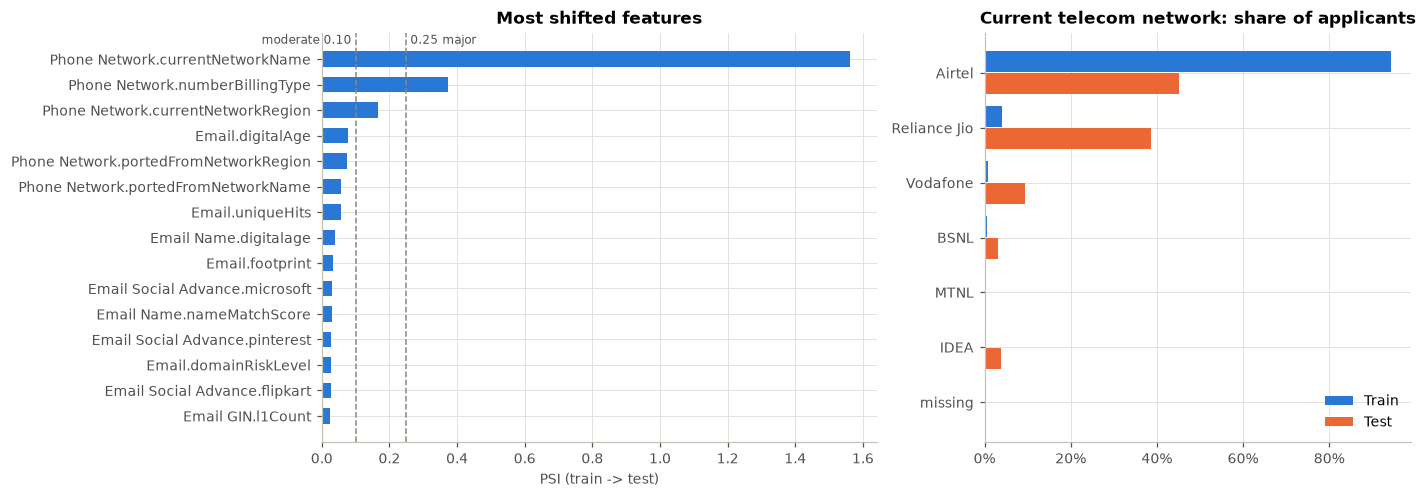

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
top = psi_tbl.head(15).iloc[::-1]
axes[0].barh(top.index.str.replace(" Attributes", ""), top["PSI"], color=BLUE, height=0.6)
for x, lab, ha in [(0.1, "moderate 0.10 ", "right"), (0.25, " 0.25 major", "left")]:
    axes[0].axvline(x, color=MUTED, linestyle="--", linewidth=1)
    axes[0].text(x, len(top) - 0.4, lab, color=INK, fontsize=8, ha=ha)
axes[0].set_xlabel("PSI (train -> test)")
axes[0].set_title("Most shifted features")

col = "Phone Network.currentNetworkName"
share = pd.DataFrame({"Train": train_all[col].fillna("missing").value_counts(normalize=True),
                      "Test": test[col].fillna("missing").value_counts(normalize=True)}).fillna(0).sort_values("Train")
pos = np.arange(len(share))
axes[1].barh(pos + 0.2, share["Train"], 0.38, color=BLUE, label="Train")
axes[1].barh(pos - 0.2, share["Test"], 0.38, color=ORANGE, label="Test")
axes[1].set_yticks(pos, share.index)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Current telecom network: share of applicants")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Observed:** the test set is **not** an i.i.d. sample of the training population.
* `Phone Network.currentNetworkName` shows a major shift: Airtel is about 94% of train but about 45% of test, and Reliance Jio grows from about 4% to about 39%. `currentNetworkRegion` and `numberBillingType` (missing 4% in train vs 23% in test) also shift.
* Typical digital ages are younger in test (median `Email Attributes.digitalAge` 407 → 181 days; `phoneNameDigitalAge` 798 → 301 days). Their decile-based PSI stays below 0.1, so this shift is milder than the telecom one.

Implications for later steps: carrier/region features may not generalise, and a train-only validation split will likely **overestimate** test performance. I will check these features' stability before relying on them, and keep this in mind when discussing limitations (it could reflect a different acquisition channel or time period).

## 11. First look at predictive signal

To connect data quality with business meaning, I compute each feature's **Information Value (IV)**, a standard screening measure in credit risk built from Weight-of-Evidence bins (missing and `-1` bins kept separate).
Rule of thumb: IV < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, > 0.3 strong. This is a univariate screen only; it is not used for feature selection on its own.

In [29]:
def information_value(x: pd.Series, target: pd.Series, numeric: bool) -> float:
    b = bucketise(x, x, numeric)
    tab = pd.crosstab(b, target)
    good = (tab[0] + 0.5) / (tab[0].sum() + 0.5)
    bad = (tab[1] + 0.5) / (tab[1].sum() + 0.5)
    return float(((good - bad) * np.log(good / bad)).sum())

iv = pd.Series({c: information_value(train[c], train[TARGET], c in NUMERIC_COLS) for c in MODEL_COLS}, name="IV").sort_values(ascending=False)
iv_df = iv.to_frame().join(doc.set_index("column")[["feature_group", "impact_direction"]])
iv_df["strength"] = pd.cut(iv_df["IV"], [-1, 0.02, 0.1, 0.3, np.inf], labels=["useless", "weak", "medium", "strong"])
print(iv_df["strength"].value_counts().to_string())
iv_df.head(20).round(3)

strength
useless    41
weak       30
medium      9
strong      1


,IV,feature_group,impact_direction,strength
Phone Social Advance.whatsapp,0.306,Social,Binary indicator,strong
Email Name Attributes.digitalage,0.183,Identity,Higher is safer,medium
Email Attributes.digitalAge,0.175,Digital Footprint,Higher is safer,medium
Email Attributes.uniqueHits,0.175,Digital Footprint,Context dependent,medium
Phone Network.numberBillingType,0.145,Telecom,Context dependent,medium
Phone Network.currentNetworkRegion,0.131,Telecom,Context dependent,medium
Email Social Advance.amazon,0.130,Social,Binary indicator,medium
Email Attributes.footprint,0.126,Digital Footprint,Higher is safer,medium
Email Social Advance.flipkart,0.116,Social,Binary indicator,medium
Email Name Attributes.emailNameDigitalAge,0.101,Identity,Higher is safer,medium


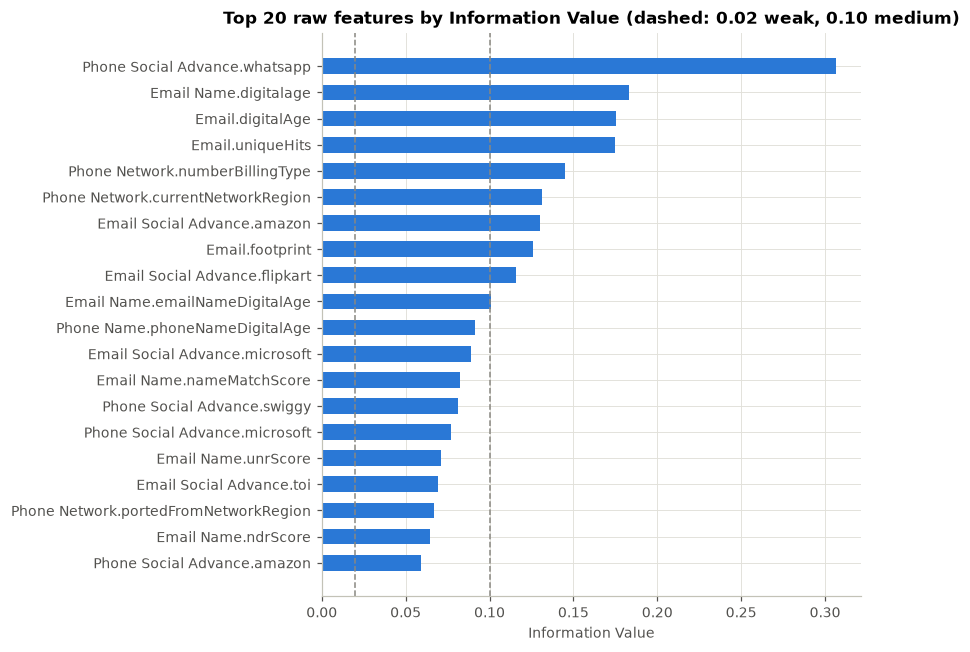

In [30]:
top = iv_df.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index.str.replace(" Attributes", ""), top["IV"], color=BLUE, height=0.6)
for x in (0.02, 0.1):
    ax.axvline(x, color=MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("Information Value")
ax.set_title("Top 20 raw features by Information Value (dashed: 0.02 weak, 0.10 medium)")
plt.tight_layout(); plt.show()

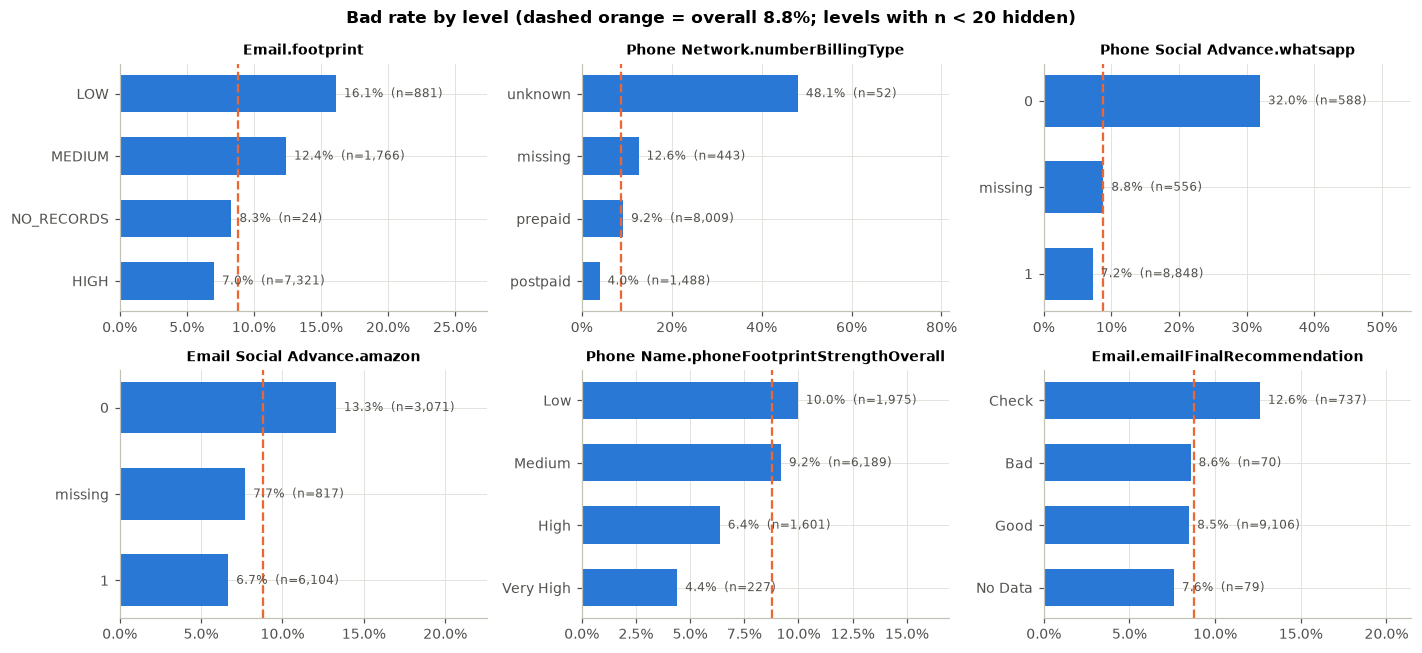

In [31]:
# Bad rate by level for key categorical / flag features (n shown per bar)
key_cats = ["Email Attributes.footprint", "Phone Network.numberBillingType", "Phone Social Advance.whatsapp",
            "Email Social Advance.amazon", "Phone Name Attributes.phoneFootprintStrengthOverall", "Email Attributes.emailFinalRecommendation"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), key_cats):
    level = train[c].map(lambda v: "missing" if pd.isna(v) else f"{v:g}" if isinstance(v, float) else str(v))
    g = train.groupby(level)[TARGET].agg(["size", "mean"])
    g = g[g["size"] >= 20].sort_values("mean")
    ax.barh(g.index, g["mean"], color=BLUE, height=0.6)
    ax.axvline(overall_bad, color=ORANGE, linewidth=1.5, linestyle="--")
    for i, (n, r) in enumerate(g[["size", "mean"]].values):
        ax.text(r, i, f"  {r:.1%}  (n={n:,.0f})", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, g["mean"].max() * 1.7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(c.replace(" Attributes", ""), fontsize=9)
fig.suptitle(f"Bad rate by level (dashed orange = overall {overall_bad:.1%}; levels with n < 20 hidden)", fontweight="bold")
plt.tight_layout(); plt.show()

**Does the data agree with the dictionary's expected direction?** Spearman correlation with Target on genuine values only (missing and `-1` excluded). *Higher is safer* should give a negative correlation; *Higher is riskier* a positive one.

In [32]:
ordinal_num = {c: train[c].map({lvl: i for i, lvl in enumerate(levels)}).astype(float) for c, levels in ORDINAL_LEVELS.items()}
rows = []
for c in NUMERIC_COLS + list(ORDINAL_LEVELS):
    exp = doc.set_index("column").loc[c, "impact_direction"]
    if exp not in ("Higher is safer", "Higher is riskier"):
        continue
    x = ordinal_num.get(c, train[c])
    ok = x.notna() & x.ne(SENTINEL) if c in NUMERIC_COLS else x.notna()
    rho = x[ok].corr(train.loc[ok, TARGET], method="spearman")
    rows.append({"column": c, "expected": exp, "n": int(ok.sum()), "spearman_vs_target": rho,
                 "agrees": (rho < 0) == (exp == "Higher is safer")})
pd.DataFrame(rows).sort_values("spearman_vs_target").round(3).reset_index(drop=True)

,column,expected,n,spearman_vs_target,agrees
0,Email Attributes.footprint,Higher is safer,9992,-0.106,True
1,Email Attributes.digitalAge,Higher is safer,9819,-0.093,True
2,Email Name Attributes.digitalage,Higher is safer,7693,-0.091,True
3,Phone Name Attributes.phoneNameDigitalAge,Higher is safer,4112,-0.078,True
4,Email Name Attributes.emailNameDigitalAge,Higher is safer,1956,-0.045,True
5,Phone Name Attributes.phoneFootprintStrengthOverall,Higher is safer,9992,-0.042,True
6,Email Name Attributes.emailFootprintStrength,Higher is safer,9992,-0.036,True
7,Email GIN.identityTrust,Higher is safer,9957,-0.030,True
8,Email GIN.l2Count,Higher is riskier,9955,-0.029,False
9,Mobile GIN.l1Count,Higher is riskier,9992,-0.028,False


**Observed signal (univariate, associational only, not causal):**
* The strongest raw signals are **digital-footprint / presence** variables: `Email Attributes.footprint` (LOW about 16% bad vs HIGH about 7%), `uniqueHits`, email digital age, and **platform presence** such as WhatsApp (not on WhatsApp: about 32% bad vs 7%) and Amazon.
* **Billing type** separates well (postpaid about 4% bad vs prepaid about 9%). The rare "unknown" level is very risky but small.
* Digital ages and footprint/trust levels agree with the dictionary's direction. The **graph (GIN) counts and confidences do not**: higher L1/L2 counts are very slightly *safer* here. Their correlations are close to zero (|ρ| < 0.03), so they carry little signal on their own.
* `nameMatchScore` is slightly positively related to delinquency among *found* records (ρ ≈ 0.04). Its useful signal is in the *not-found* (`-1`) state (bad rate 9.9% vs 5.5%). The same holds for the other email-name fields, so "was this identity found at all?" matters more than the score value.
* `currentNetworkRegion` has medium IV but shifts between train and test (Section 10), so its signal may not transfer.
* The direct fraud flags (`fraudNetwork`, `ccrp`) are too rare or constant to be useful. **This is a credit-delinquency problem, not a fraud problem.**
* Individually, most features are weak (IV < 0.1). Good performance will need **combined / aggregated features** (e.g. social-presence counts, footprint composites, identity-consistency scores), which motivates the feature-engineering step.

## 12. Summary of data-quality findings and implications

| # | Finding | Evidence | Treatment in the modelling pipeline |
|---|---|---|---|
| 1 | Target has 8 unlabelled rows (`"NaT"`) | 9,114 good / 878 bad / 8 NaT | Exclude from training & validation |
| 2 | Class imbalance, 8.8% bad (about 10:1) | Section 3 | Stratified splits; ROC-AUC, PR-AUC, KS rather than accuracy; class weights; deliberate threshold choice |
| 3 | Missing values hidden as the string `"NaT"`; raw dtypes wrong | 0 explicit NaN, but up to 100% `"NaT"` per column; 50 mixed-type columns | `standardise()` converts tokens to NaN and casts to semantic types |
| 4 | `-1` sentinel = "not found in Bureau network" | up to 84% of rows in email-name fields | Keep as information: missing-indicator flags / separate bin, not mean imputation |
| 5 | Missingness is structural and informative | Whole service blocks missing together; bad rate differs missing vs present | Block-level "service returned" flags; impute numerics after flagging |
| 6 | 7 constant columns; 2 non-constant identical pairs | Section 6–7 | Drop constants, `Phone Name Attributes.businessNameDetected` and `Email GIN.fraudCount` |
| 7 | Near-constant fraud flags | `Email GIN.fraudNetwork` = 1 in 7 rows, `Email GIN.fraud` never 1 | Low priority; may be folded into a combined risk flag |
| 8 | Implausible / capped values | Phone age of about 100 years; GIN counts about 500 | Cap at plausible limits / winsorise; flag extreme graph counts |
| 9 | No duplicate records or repeat applicants; no train–test overlap | Section 6 | No action needed |
| 10 | PII and identifier columns | `name`, `UPIname`, masked `phoneNumber`, `UID` | Never used raw; only derived non-identifying features (e.g. name-match similarity) |
| 11 | Major train→test shift | Carrier mix (Airtel 94% → 45%), billing-type missingness, younger digital ages | Check feature stability, avoid over-relying on carrier/region, flag as key limitation |
| 12 | No loan / repayment / income variables | Section 2 | Expect moderate discrimination; state as a limitation |

**Assumptions made:** `Target = 1` means delinquent (definition and observation window not provided); `-1` in age/score fields means "not found" (documented only for `Email Attributes.digitalAge`); interpretations of undocumented columns as listed in Section 2.

In [33]:
# Hand-off to feature engineering: cleaned frames and the column lists decided above
REDUNDANT_COLS = ["Phone Name Attributes.businessNameDetected", "Email GIN.fraudCount"]
DROP_COLS = [ID_COL] + PII_COLS + DATE_COLS + CONSTANT_COLS + REDUNDANT_COLS
BASE_FEATURES = [c for c in FEATURES if c not in DROP_COLS]
print(f"train (labelled): {train.shape}, test: {test.shape}")
print(f"Columns dropped as raw inputs: {len(set(DROP_COLS))}; base features carried forward: {len(BASE_FEATURES)}")
print("(revocationMonth is kept aside for feature engineering, e.g. 'months since number was recycled'.)")

train (labelled): (9992, 94), test: (5000, 93)
Columns dropped as raw inputs: 14; base features carried forward: 79
(revocationMonth is kept aside for feature engineering, e.g. 'months since number was recycled'.)
